# RQ4 — Writing Style Analysis

What linguistic and structural characteristics distinguish GPT, Claude, and Gemini?

Standalone extraction of the existing `CNN.ipynb` RQ4 analysis. Run **Runtime → Run all** in Google Colab using a CPU runtime. No CNN training, weights, vocabulary, or GPU are needed.

[Open in Colab](https://colab.research.google.com/github/palashDoshi1/CMPSC-448-Midterm-Project/blob/main/CNN_RQ4_Writing_Style_Analysis.ipynb)

Source revision: `bcd4d4ee89b94f4e76aa085099480ee74b262a9b`. The feature function, aggregation, plotting code, and results interpretation are preserved. Only loading, output location, verification, and optional exports are added.

## 1. Libraries

Colab provides pandas, NumPy, and Matplotlib. Version information is exported with results.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

## 2. Load and validate the original data

Load the original 378/81/81 split CSVs from the pinned revision, then concatenate in train, validation, test order. Analyze the full output text without classifier truncation or preprocessing.

In [2]:
# Immutable source revision: the same split files used by CNN.ipynb.
SOURCE_REVISION = "bcd4d4ee89b94f4e76aa085099480ee74b262a9b"
BASE = f"https://raw.githubusercontent.com/palashDoshi1/CMPSC-448-Midterm-Project/{SOURCE_REVISION}/data/"
from urllib.request import urlopen
import hashlib, io, json, platform
frames = {}
data_hashes = {}
for split, filename in [("train", "train.csv"), ("validation", "validation.csv"), ("test", "test.csv")]:
    with urlopen(BASE + filename) as response:
        raw = response.read()
    data_hashes[filename] = hashlib.sha256(raw).hexdigest()
    frames[split] = pd.read_csv(io.BytesIO(raw))
train_df, val_df, test_df = frames["train"], frames["validation"], frames["test"]
LABEL_MAP = {"gpt": 0, "claude": 1, "gemini": 2}


In [3]:
required = {"prompt_id", "category", "model", "input", "output"}
# Verify required columns
for frame in [train_df, val_df, test_df]:
    assert required.issubset(frame.columns)

# Verify expected dataset sizes
assert len(train_df) == 378
assert len(val_df) == 81
assert len(test_df) == 81

# Verify no prompt overlap
train_ids = set(train_df["prompt_id"])
val_ids = set(val_df["prompt_id"])
test_ids = set(test_df["prompt_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Verify labels, missing values, and duplicates
for frame in [train_df, val_df, test_df]:

    assert set(frame["model"].unique()) == set(LABEL_MAP)

    assert not frame[list(required)].isnull().any().any()

    assert not frame.duplicated(
        subset=["prompt_id", "model"]
    ).any()

    # Each prompt should have responses from all 3 LLMs
    assert frame.groupby("prompt_id")["model"].nunique().eq(3).all()

print("All validation checks passed!")
print("No prompt overlap between train, validation, and test.")
print("Ready for descriptive RQ4 analysis!")

All validation checks passed!
No prompt overlap between train, validation, and test.
Ready for descriptive RQ4 analysis!


In [4]:
# Prepare data for RQ3 and RQ4
analysis_df = pd.concat(
    [
        train_df.assign(original_split="train"),
        val_df.assign(original_split="validation"),
        test_df.assign(original_split="test"),
    ],
    ignore_index=True,
)

assert not analysis_df.duplicated(
    subset=["prompt_id", "model"]
).any()

print("Responses by category and model:")
print(pd.crosstab(analysis_df["category"], analysis_df["model"]))

print("\nUnique prompts per category:")
print(
    analysis_df.groupby("category")["prompt_id"]
    .nunique()
    .sort_index()
)

print("\nEach prompt belongs to one category:")
print(
    analysis_df.groupby("prompt_id")["category"]
    .nunique().eq(1).all()
)

Responses by category and model:
model            claude  gemini  gpt
category                            
cs_software          30      30   30
finance_banking      30      30   30
general_writing      30      30   30
math_logic           30      30   30
sports               30      30   30
stocks_trading       30      30   30

Unique prompts per category:
category
cs_software        30
finance_banking    30
general_writing    30
math_logic         30
sports             30
stocks_trading     30
Name: prompt_id, dtype: int64

Each prompt belongs to one category:
True


In [5]:
assert len(analysis_df) == 540
assert analysis_df.groupby("model").size().to_dict() == {"claude": 180, "gemini": 180, "gpt": 180}
assert pd.crosstab(analysis_df["category"], analysis_df["model"]).eq(30).all().all()
assert analysis_df.groupby("prompt_id")["category"].nunique().eq(1).all()

## 3. Original feature definitions

Unicode word matching defines response length. Diversity uses lowercased words and every overlapping 50-word window; shorter responses receive NaN and are excluded from MATTR summaries. Formatting uses the original Markdown marker rules. Punctuation includes non-word, non-whitespace symbols. These are descriptive measurements, with no new statistical tests.

In [6]:
# Local Colab output; Drive is optional in the final export cell.
rq4_dir = Path("/content/rq4_outputs") if Path("/content").exists() else Path("rq4_outputs")
rq4_dir.mkdir(parents=True, exist_ok=True)
print("Output directory:", rq4_dir.resolve())

Output directory: /content/rq4_outputs


In [7]:
def rq4_style_features(text):
    text = str(text)

    # Unicode word matches; lowercased only for diversity measurement.
    words = re.findall(r"\b\w+\b", text, flags=re.UNICODE)
    lower_words = [word.lower() for word in words]
    word_count = len(words)
    lines = text.splitlines()
    nonempty_lines = [line for line in lines if line.strip()]

    # Fixed 50-word windows reduce the length bias of ordinary TTR.
    if word_count >= 50:
        mattr = np.mean([
            len(set(lower_words[i:i + 50])) / 50
            for i in range(word_count - 49)
        ])
    else:
        mattr = np.nan

    heading_lines = sum(
        bool(re.match(r"^\s{0,3}#{1,6}\s+", line))
        for line in lines
    )
    list_lines = sum(
        bool(re.match(r"^\s*(?:[-*+]|\d+[.)])\s+", line))
        for line in lines
    )
    punctuation_count = len(re.findall(r"[^\w\s]", text))

    return {
        "word_count": word_count,
        "character_count": len(text),
        "mean_word_length": (
            np.mean([len(word) for word in words])
            if words else np.nan
        ),
        "type_token_ratio": (
            len(set(lower_words)) / word_count
            if word_count else np.nan
        ),
        "mattr_50": mattr,
        "nonempty_lines": len(nonempty_lines),
        "heading_lines": heading_lines,
        "list_lines": list_lines,
        "punctuation_per_100_words": (
            100 * punctuation_count / word_count
            if word_count else np.nan
        ),
        "has_heading": int(heading_lines > 0),
        "has_list": int(list_lines > 0),
        "has_code_fence": int("```" in text or "~~~" in text),
        "has_bold_marker": int("**" in text or "__" in text),
    }




## 4. Response features and summaries

Export the original three CSVs: per-response features, model summaries (mean/median/std/count), and category/model means.

In [8]:
rq4_features = analysis_df[
    ["prompt_id", "category", "model", "original_split"]
].reset_index(drop=True).copy()

feature_values = pd.DataFrame([
    rq4_style_features(text) for text in analysis_df["output"]
])
rq4_features = pd.concat([rq4_features, feature_values], axis=1)

feature_columns = feature_values.columns.tolist()

# Overall summaries
rq4_summary = rq4_features.groupby("model")[
    feature_columns
].agg(["mean", "median", "std", "count"])

# Category-specific summaries help check whether patterns vary by task.
rq4_by_category = rq4_features.groupby(
    ["category", "model"]
)[feature_columns].mean()

rq4_features.to_csv(rq4_dir / "rq4_response_features.csv", index=False)
rq4_summary.to_csv(rq4_dir / "rq4_summary_by_model.csv")
rq4_by_category.to_csv(rq4_dir / "rq4_summary_by_category_model.csv")

print("Mean writing-style measurements:")
display(
    rq4_features.groupby("model")[[
        "word_count",
        "mean_word_length",
        "type_token_ratio",
        "mattr_50",
        "punctuation_per_100_words",
    ]].mean().round(4)
)

print("\nPercentage of responses containing formatting markers:")
formatting_columns = [
    "has_heading", "has_list", "has_code_fence", "has_bold_marker"
]
display(
    (
        rq4_features.groupby("model")[formatting_columns].mean()
        * 100
    ).round(2)
)

print("\nResponses eligible for 50-word lexical-diversity measurement:")
print(rq4_features.groupby("model")["mattr_50"].count())



Mean writing-style measurements:


,word_count,mean_word_length,type_token_ratio,mattr_50,punctuation_per_100_words
model,,,,,
claude,629.7111,4.9244,0.5055,0.8259,26.0010
gemini,328.7778,5.6832,0.6592,0.8625,41.2468
gpt,459.2722,5.7827,0.6309,0.8592,26.5300



Percentage of responses containing formatting markers:


,has_heading,has_list,has_code_fence,has_bold_marker
model,,,,
claude,0.56,61.67,0.00,19.44
gemini,39.44,33.33,23.89,46.67
gpt,30.56,19.44,5.00,25.56



Responses eligible for 50-word lexical-diversity measurement:
model
claude    180
gemini    180
gpt       179
Name: mattr_50, dtype: int64


## 5. Verify existing reported values

Stop on a mismatch instead of silently replacing report numbers.

In [9]:
# Compare rounded values with the existing CNN.ipynb RQ4 table.
model_order = ["gpt", "claude", "gemini"]
means = rq4_features.groupby("model").mean(numeric_only=True).reindex(model_order)
expected = {
    "word_count": ([459.27, 629.71, 328.78], 2),
    "mattr_50": ([0.8592, 0.8259, 0.8625], 4),
    "punctuation_per_100_words": ([26.53, 26.00, 41.25], 2),
    "has_heading": ([30.56, 0.56, 39.44], 2),
    "has_list": ([19.44, 61.67, 33.33], 2),
    "has_code_fence": ([5.00, 0.00, 23.89], 2),
    "has_bold_marker": ([25.56, 19.44, 46.67], 2),
}
for feature, (values, digits) in expected.items():
    actual = means[feature] * (100 if feature.startswith("has_") else 1)
    np.testing.assert_allclose(actual.round(digits), values, rtol=0, atol=1e-10)
assert rq4_features.groupby("model")["mattr_50"].count().to_dict() == {"claude": 180, "gemini": 180, "gpt": 179}
print("All seven reported measurements match CNN.ipynb at its displayed precision.")


All seven reported measurements match CNN.ipynb at its displayed precision.


## 6. Original report figures

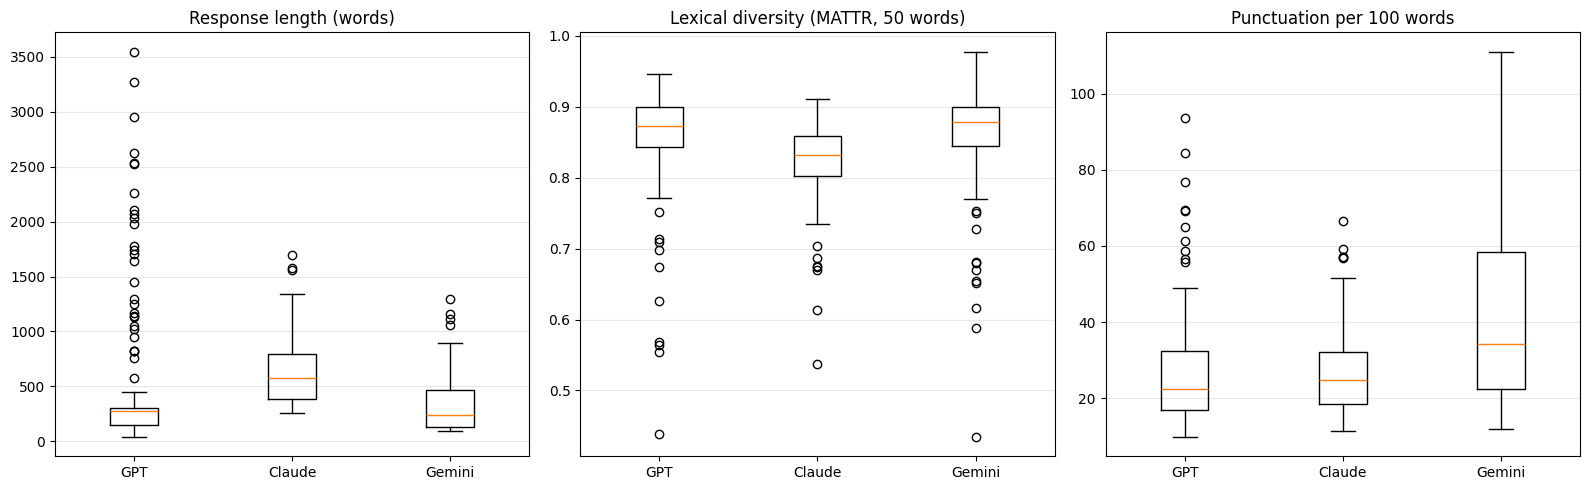

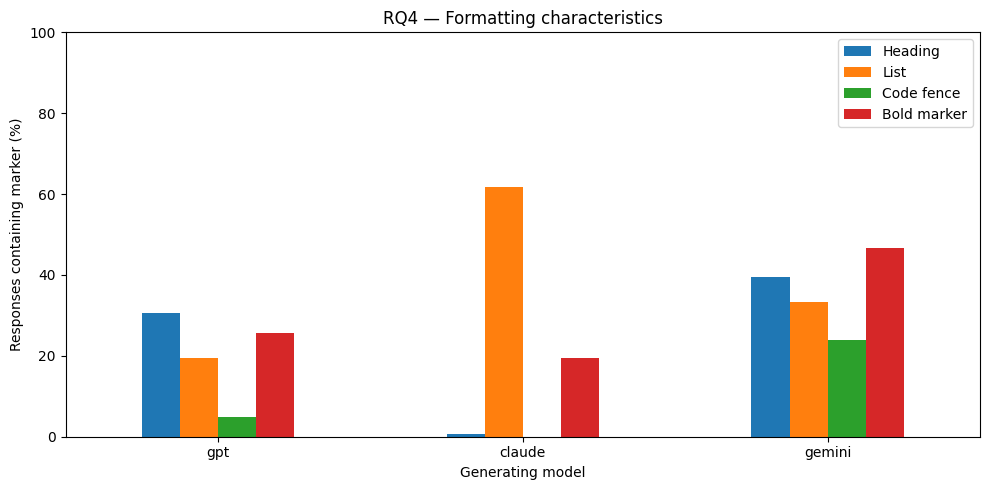


RQ4 files saved to: /content/rq4_outputs


In [10]:
# Distribution plots
model_order = ["gpt", "claude", "gemini"]
plot_features = [
    ("word_count", "Response length (words)"),
    ("mattr_50", "Lexical diversity (MATTR, 50 words)"),
    ("punctuation_per_100_words", "Punctuation per 100 words"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (feature, title) in zip(axes, plot_features):
    groups = [
        rq4_features.loc[
            rq4_features["model"].eq(name), feature
        ].dropna().to_numpy()
        for name in model_order
    ]
    ax.boxplot(groups)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["GPT", "Claude", "Gemini"])
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(rq4_dir / "rq4_style_distributions.png", dpi=200)
plt.show()
plt.close(fig)

# Formatting-frequency plot
formatting_rates = (
    rq4_features.groupby("model")[formatting_columns]
    .mean().reindex(model_order) * 100
)
formatting_rates.columns = [
    "Heading", "List", "Code fence", "Bold marker"
]
ax = formatting_rates.plot.bar(figsize=(10, 5))
ax.set_ylabel("Responses containing marker (%)")
ax.set_xlabel("Generating model")
ax.set_title("RQ4 — Formatting characteristics")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.figure.tight_layout()
ax.figure.savefig(rq4_dir / "rq4_formatting_rates.png", dpi=200)
plt.show()
plt.close(ax.figure)

print("\nRQ4 files saved to:", rq4_dir)

## RQ4: Writing-Style Results and Interpretation

We analyzed all 540 responses, with 180 responses per model and balanced representation across six task categories. This descriptive analysis was performed after the classification experiments and was not used to tune the classifiers.

| Measurement | GPT | Claude | Gemini |
|---|---:|---:|---:|
| Mean response length (words) | 459.27 | 629.71 | 328.78 |
| Mean lexical diversity (MATTR-50) | 0.8592 | 0.8259 | 0.8625 |
| Mean punctuation/symbol count per 100 words | 26.53 | 26.00 | 41.25 |
| Responses with heading markers (%) | 30.56 | 0.56 | 39.44 |
| Responses with list markers (%) | 19.44 | 61.67 | 33.33 |
| Responses with code fences (%) | 5.00 | 0.00 | 23.89 |
| Responses with bold markers (%) | 25.56 | 19.44 | 46.67 |

Claude produced the longest responses on average and used list markers most frequently. Gemini produced the shortest responses on average and used heading, code-fence, and bold markers most frequently. GPT showed intermediate average response length.

Lexical diversity was measured using the moving-average type-token ratio over 50-word windows (MATTR-50), reducing the length dependence of ordinary type-token ratio. Gemini and GPT had higher mean MATTR-50 than Claude, although their distributions overlapped. All Claude and Gemini responses qualified for this measurement; one GPT response shorter than 50 words was excluded.

These observations identify linguistic and structural differences within the collected dataset. They do not establish which features the CNN or LSTM actually used, nor whether the differences generalize to other prompts or model versions. Formatting detection uses simple marker rules, and the punctuation measure includes symbols such as Markdown and code characters. No statistical significance tests or feature-removal experiments were performed.

## 7. Export and optional download

The two report PNGs and supporting CSVs are saved in `rq4_outputs`. The ZIP also contains provenance and formatting rates. Enable the switches below to download the ZIP or copy results to Drive.

In [11]:
# Extra export of the already-computed formatting rates and run provenance.
formatting_rates.to_csv(rq4_dir / "rq4_formatting_rates.csv")
manifest = {
    "source_revision": SOURCE_REVISION,
    "source_notebook": "CNN.ipynb (cells 21–23)",
    "data_sha256": data_hashes,
    "responses": len(analysis_df),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "matplotlib": matplotlib.__version__},
}
(rq4_dir / "rq4_provenance.json").write_text(json.dumps(manifest, indent=2))
import shutil
archive_path = shutil.make_archive(str(rq4_dir.parent / "CNN_RQ4_results"), "zip", rq4_dir)
print("Results archive:", archive_path)
for path in sorted(rq4_dir.iterdir()):
    print(path.name)


Results archive: /content/CNN_RQ4_results.zip
rq4_formatting_rates.csv
rq4_formatting_rates.png
rq4_provenance.json
rq4_response_features.csv
rq4_style_distributions.png
rq4_summary_by_category_model.csv
rq4_summary_by_model.csv


In [12]:
# Optional: enable either switch to download or preserve results in Google Drive.
DOWNLOAD_ZIP = False
SAVE_TO_DRIVE = False
if DOWNLOAD_ZIP:
    from google.colab import files
    files.download(archive_path)
if SAVE_TO_DRIVE:
    from google.colab import drive
    from datetime import datetime
    drive.mount("/content/drive")
    destination = Path("/content/drive/MyDrive/CMPSC448/RQ4") / datetime.now().strftime("%Y%m%d_%H%M%S")
    shutil.copytree(rq4_dir, destination)
    print("Saved to:", destination)
